/Users/evandaniels/Research/runs/whistler/di_0.5_verlet_cfl0.75: 1001 outputs, Nx = 800, Lx = 6.2832, di = 0.5
max|Bz| over the run = 1.410e-03

  m      k   k di | w_L theory  w_L meas  err % | w_R theory  w_R meas  err %
  1   1.00   0.50 |      0.781       n/d    n/d |      1.281     1.281  -0.00
  2   2.00   1.00 |      1.236     1.236  -0.00 |      3.236     3.236  -0.00
  3   3.00   1.50 |      1.500     1.500   0.01 |      6.000     6.000  -0.00
  4   4.00   2.00 |      1.657     1.657   0.02 |      9.657     9.656  -0.01
  5   5.00   2.50 |      1.754     1.755   0.04 |     14.254    14.252  -0.02
  6   6.00   3.00 |      1.817     1.818   0.05 |     19.817    19.812  -0.02
  7   7.00   3.50 |      1.859     1.860   0.08 |     26.359    26.349  -0.04
  8   8.00   4.00 |      1.889     1.891   0.10 |     33.889    33.872  -0.05
  9   9.00   4.50 |      1.910     1.912   0.13 |     42.410    42.383  -0.06
 10  10.00   5.00 |      1.926     1.929   0.16 |     51.926    51.883  -0.

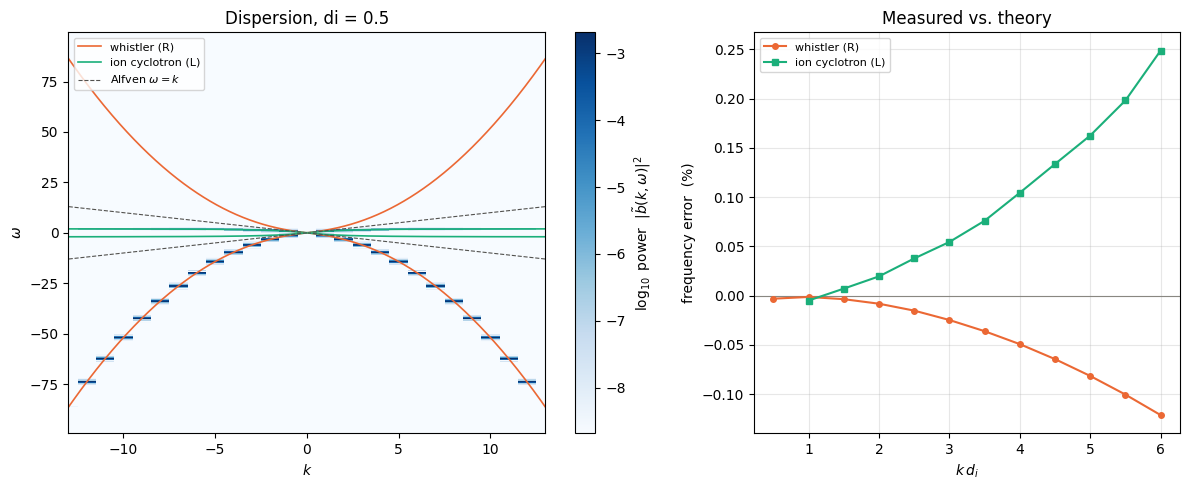

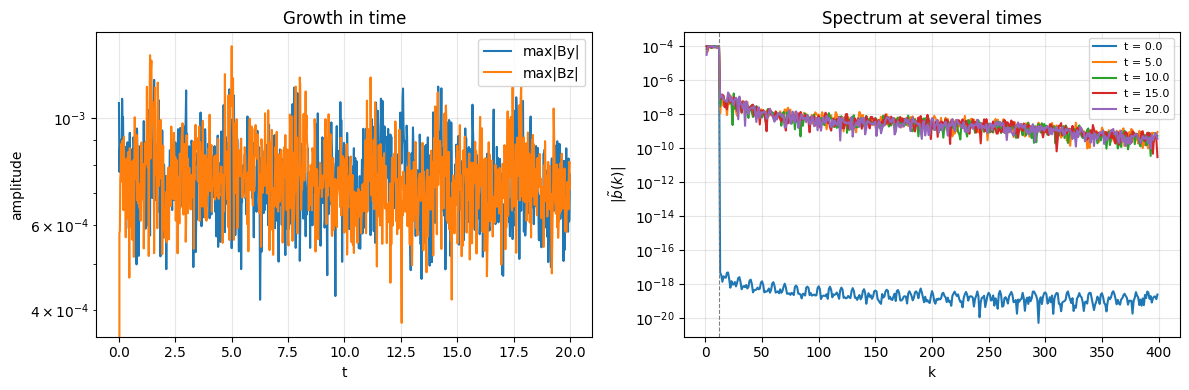

peak |Bz| = 6.771e-04 at x = 5.7373 (cell 730), y-cell 0
rank boundaries at x = [0.6322, 1.2606, 1.8889, 2.5172, 3.1455, 3.7738, 4.4022, 5.0305, 5.6588]
|Bz| across y at that x: [0.00067711 0.00067711 0.00067711 0.00067711 0.00067711 0.00067711
 0.00067711 0.00067711]


In [10]:
"""
whistler_analysis.py -- linear dispersion test for the Hall MHD solver (problem = 2)

Setup (see initial_conditions block): uniform plasma, B0 along x, small By made of
modes k_m = m * 2*pi/Lx, v = 0, Bz = 0. In Hall MHD each parallel-propagating mode
splits into two circularly polarized branches (normalized units, vA = B0/sqrt(rho0) = 1):

    whistler       (R):  omega_R = k * ( sqrt(1 + (k di/2)^2) + k di/2 )   -> di * k^2 at large k
    ion-cyclotron  (L):  omega_L = k * ( sqrt(1 + (k di/2)^2) - k di/2 )   -> 1/di (= Omega_ci)

With di = 0 both collapse to the Alfven wave omega = k, and Bz must stay zero.

The script builds b(x,t) = By + i Bz (averaged over y), Fourier transforms it in x
and t, plots the power in the (k, omega) plane with the theory curves on top, and
prints measured vs. theoretical frequencies for every excited mode.

File mapping (writeout.cc): b2 = By, b3 = Bz
"""

import os
import glob
import numpy as np
import matplotlib.pyplot as plt

# ----------------------------------------------------------------------------
# Settings -- edit these to match the run
# ----------------------------------------------------------------------------
# RUN_DIR = os.path.expanduser('~/Research/runs/whistler/di_0.5')
# RUN_DIR = os.path.expanduser('~/Research/runs/whistler/di_0.5_cflem0.2')
# RUN_DIR = os.path.expanduser('~/Research/runs/whistler/di_0_cflem0.2')
# RUN_DIR = os.path.expanduser('~/Research/runs/whistler/di_0_cflem0.2_eta0.009')
RUN_DIR = os.path.expanduser('~/Research/runs/whistler/di_0.5_verlet_cfl0.75')

DI      = 0.5            # must match 'di' in the input file
P       = 10           # MPI ranks the test was run with
DT_OUT  = 0.02         # output interval
T_FINAL = 20.0         # outputs after this are dropped (repeated final writeout)
M_MODES = 12           # modes excited in the initial condition (k_m = m * 2pi/Lx)

# ----------------------------------------------------------------------------
def load_field(name, n):
    return np.vstack([np.loadtxt(f'{RUN_DIR}/{name}_files/{name}_p{p:03d}_{n:03d}', ndmin=2)
                      for p in range(P)])


def omega_theory(k, di):
    s = np.sqrt(1.0 + (k * di / 2.0) ** 2)
    return k * (s + k * di / 2.0), k * (s - k * di / 2.0)        # (whistler R, ion-cyclotron L)


def spectral_peaks(S, w, n_peaks=2, floor=0.02):
    """|omega| of the strongest local maxima of S(omega), merging +/- duplicates."""
    i = np.where((S[1:-1] > S[:-2]) & (S[1:-1] >= S[2:]) & (S[1:-1] > floor * S.max()))[0] + 1
    i = i[np.argsort(S[i])[::-1]]
    found = []
    dw = w[1] - w[0]
    for idx in i:
        # parabolic refinement of the peak position
        a, b, c = np.log(S[idx - 1] + 1e-300), np.log(S[idx] + 1e-300), np.log(S[idx + 1] + 1e-300)
        off = 0.5 * (a - c) / (a - 2 * b + c) if (a - 2 * b + c) != 0 else 0.0
        wabs = abs(w[idx] + off * dw)
        if all(abs(wabs - f) > 2 * abs(dw) for f in found):
            found.append(wabs)
        if len(found) == n_peaks:
            break
    return sorted(found)


# ----------------------------------------------------------------------------
x = np.concatenate([np.loadtxt(f'{RUN_DIR}/mesh_files/x_p{p:03d}', ndmin=1) for p in range(P)])
N = len(glob.glob(f'{RUN_DIR}/b2_files/b2_p000_*'))
ns = [n for n in range(N) if n * DT_OUT <= T_FINAL + 1e-9]
t = np.array([n * DT_OUT for n in ns])
dx = x[1] - x[0]
Lx = dx * len(x)
print(f'{RUN_DIR}: {len(ns)} outputs, Nx = {len(x)}, Lx = {Lx:.4f}, di = {DI}')

b = np.empty((len(ns), len(x)), dtype=complex)
for i, n in enumerate(ns):
    by = load_field('b2', n).mean(axis=1)          # uniform in y: average it out
    bz = load_field('b3', n).mean(axis=1)
    b[i] = by + 1j * bz
b -= b.mean(axis=1, keepdims=True)                  # drop k = 0

print(f'max|Bz| over the run = {np.abs(b.imag).max():.3e}'
      + ('   (di = 0: should be ~0)' if DI == 0 else ''))

# ---- Fourier transforms: x -> k, then t -> omega (Hann window, zero-padded) ----
Bk = np.fft.fft(b, axis=1) / len(x)                 # [t, k]
k = 2 * np.pi * np.fft.fftfreq(len(x), dx)
win = np.hanning(len(t))[:, None]
NPAD = 8 * len(t)
Bkw = np.fft.fft(Bk * win, n=NPAD, axis=0)          # [omega, k]
# numpy's kernel is exp(-i w t): a wave exp(i(kx - w0 t)) peaks at w = -w0, so flip the sign
w = -2 * np.pi * np.fft.fftfreq(NPAD, DT_OUT)
P_kw = np.abs(Bkw) ** 2

# ---- per-mode comparison with theory ----
# Each branch is searched for in a window around its own predicted frequency, and only
# counted if its peak stands well above the noise there. A pure-B initial perturbation
# (v = 0) excites the ion-cyclotron branch only weakly at large k di (that mode is mostly
# ion motion), so 'n/d' (not detected) at high k is expected, not a solver failure.
WINDOW = 0.25          # search |omega| within +/- 25% of the theory value
MIN_REL = 1e-4         # branch peak must exceed this fraction of the strongest peak at that k


def branch_peak(spec, w, w_th):
    """Refined |omega| of the strongest peak within the window around w_th, or nan."""
    sel = np.where((np.abs(np.abs(w) - w_th) <= WINDOW * w_th))[0]
    if sel.size < 3 or spec[sel].max() < MIN_REL * spec.max():
        return np.nan, 0.0
    i = sel[np.argmax(spec[sel])]
    if i == 0 or i == len(spec) - 1:
        return abs(w[i]), spec[i] / spec.max()
    a, b, c = (np.log(spec[i + d] + 1e-300) for d in (-1, 0, 1))
    off = 0.5 * (a - c) / (a - 2 * b + c) if (a - 2 * b + c) != 0 else 0.0
    return abs(w[i] + off * (w[1] - w[0])), spec[i] / spec.max()


fmt = lambda v: f'{v:9.3f}' if np.isfinite(v) else '      n/d'
fmte = lambda v: f'{v:6.2f}' if np.isfinite(v) else '   n/d'
print(f'\n{"m":>3} {"k":>6} {"k di":>6} | {"w_L theory":>10} {"w_L meas":>9} {"err %":>6} |'
      f' {"w_R theory":>10} {"w_R meas":>9} {"err %":>6}')
errs = []
order = np.argsort(w)
ws_sorted = w[order]
for m in range(1, M_MODES + 1):
    km = m * 2 * np.pi / Lx
    wR, wL = omega_theory(km, DI)
    spec = (P_kw[:, np.argmin(np.abs(k - km))] + P_kw[:, np.argmin(np.abs(k + km))])[order]
    meas_R, _ = branch_peak(spec, ws_sorted, wR)
    if DI == 0:
        meas_L = meas_R
    else:
        # the two branches overlap in frequency at low k: only trust L if its window
        # does not reach the R peak
        meas_L, _ = branch_peak(spec, ws_sorted, wL) if wL * (1 + WINDOW) < wR * (1 - WINDOW) else (np.nan, 0)
    eL, eR = 100 * (meas_L - wL) / wL, 100 * (meas_R - wR) / wR
    errs.append((km, eL, eR))
    print(f'{m:>3} {km:>6.2f} {km*DI:>6.2f} | {wL:>10.3f} {fmt(meas_L)} {fmte(eL)} |'
          f' {wR:>10.3f} {fmt(meas_R)} {fmte(eR)}')

# ---- figure: dispersion diagram + frequency error vs k ----
kmax = (M_MODES + 1) * 2 * np.pi / Lx
wmax = 1.15 * omega_theory(kmax, DI)[0]
ks, ws = np.fft.fftshift(k), np.fft.fftshift(w)
Pplot = np.fft.fftshift(P_kw)
kk = np.linspace(0, kmax, 400)
thR, thL = omega_theory(kk, DI)

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(12, 5), gridspec_kw={'width_ratios': [1.4, 1]})
pc = ax.pcolormesh(ks, ws, np.log10(Pplot + 1e-30), shading='auto', cmap='Blues',
                   vmin=np.log10(Pplot.max()) - 6, vmax=np.log10(Pplot.max()))
fig.colorbar(pc, ax=ax, label=r'$\log_{10}$ power  $|\tilde b(k,\omega)|^2$')
for sgn_k in (1, -1):
    for sgn_w in (1, -1):
        lbl = (sgn_k == 1 and sgn_w == 1)
        ax.plot(sgn_k * kk, sgn_w * thR, color='#eb6834', lw=1.2, label='whistler (R)' if lbl else None)
        ax.plot(sgn_k * kk, sgn_w * thL, color='#1baf7a', lw=1.2, label='ion cyclotron (L)' if lbl else None)
        ax.plot(sgn_k * kk, sgn_w * kk, color='#52514e', lw=0.8, ls='--',
                label=r'Alfven $\omega = k$' if lbl else None)
ax.set(xlim=(-kmax, kmax), ylim=(-wmax, wmax), xlabel=r'$k$', ylabel=r'$\omega$',
       title=f'Dispersion, di = {DI}')
ax.legend(fontsize=8, loc='upper left')

e = np.array(errs)
ax2.axhline(0, color='#898781', lw=0.8)
ax2.plot(e[:, 0] * DI if DI else e[:, 0], e[:, 2], 'o-', color='#eb6834', ms=4, label='whistler (R)')
if DI != 0:
    ax2.plot(e[:, 0] * DI, e[:, 1], 's-', color='#1baf7a', ms=4, label='ion cyclotron (L)')
ax2.set(xlabel=r'$k\,d_i$' if DI else r'$k$', ylabel='frequency error  (%)',
        title='Measured vs. theory')
ax2.grid(alpha=0.3)
ax2.legend(fontsize=8)
fig.tight_layout()
plt.show()

# ---- growth diagnostic: amplitude vs time, and which k is growing ----
amp_by = np.array([np.abs(load_field('b2', n)).max() for n in ns])
amp_bz = np.array([np.abs(load_field('b3', n)).max() for n in ns])
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
a1.semilogy(t, amp_by, label='max|By|'); a1.semilogy(t, amp_bz, label='max|Bz|')
a1.set(xlabel='t', ylabel='amplitude', title='Growth in time'); a1.legend(); a1.grid(alpha=0.3)
kpos = k > 0
for frac in (0.0, 0.25, 0.5, 0.75, 1.0):
    i = int(frac*(len(ns) - 1))
    a2.semilogy(k[kpos], np.abs(Bk[i, kpos]) + 1e-30, label=f't = {t[i]:.1f}')
a2.axvline(M_MODES*2*np.pi/Lx, color='gray', ls='--', lw=0.8)
a2.set(xlabel='k', ylabel=r'$|\tilde b(k)|$', title='Spectrum at several times'); a2.legend(fontsize=8); a2.grid(alpha=0.3)
fig.tight_layout(); plt.show()

n_b = int(round(15.5/DT_OUT))                      # a frame inside the third burst
bz = load_field('b3', n_b)
j, kk = np.unravel_index(np.argmax(np.abs(bz)), bz.shape)
print(f'peak |Bz| = {np.abs(bz).max():.3e} at x = {x[j]:.4f} (cell {j}), y-cell {kk}')
print('rank boundaries at x =', [round(x[p*len(x)//P], 4) for p in range(1, P)])
print('|Bz| across y at that x:', np.abs(bz[j, :]))